# Regular TCT vs Adaptive TCT — The Cost of (Not) Adapting

Regular (non-adaptive) TCT requires fixing a target number of top rounds τ **upfront** and
prepaying the composition cost for all τ hits at registration:

    K_τ^std = (1 + α_τ) · τ / q,   α_τ = (β + √(β² + 2βτ)) / τ,   β = ln(1/δ)

This uses the *full* δ budget for one fixed target, giving a smaller K_τ than adaptive —
but it requires knowing τ in advance.

Adaptive TCT pays *incrementally*: K_1 at registration, then ΔK at each actual hit.
The total after k hits equals K_{k+1} — exactly what is needed. It splits δ across all
future k via the Zeta-2 allocation (δ_k = 6/(π²k²)·δ), which costs slightly more per hit
but never requires knowing the stopping time upfront.

| Panel | Scenario | τ vs actual tops | Effect |
|-------|----------|-----------------|--------|
| 1 | Right guess | τ ≈ actual | Both perform similarly |
| 2 | Too little  | τ < actual | Re-registration overhead → earlier dropout |
| 3 | Too much    | τ > actual | Over-prepayment → immediate dropout |

`TAU_MATCH`, `TAU_LOW`, and `TAU_HIGH` are configurable below.

In [1]:
import sys
sys.path.insert(0, '..')

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from simulation.accountants.adaptive_tct import AdaptiveTCTAccountant
from simulation.accountants.base import PrivacyAccountant
from simulation.calibration import q_from_epsilon, set_threshold_for_hit_rate
from simulation.datasets import generate_synthetic_population, PopulationConfig
from simulation.population import User
from simulation.query import compute_round_conversions, laplace_threshold_query

plt.rcParams.update({
    'figure.dpi': 150, 'font.size': 10, 'axes.labelsize': 10,
    'axes.titlesize': 11, 'legend.fontsize': 8.5,
    'lines.linewidth': 2.0, 'axes.spines.top': False, 'axes.spines.right': False,
})

# ── Simulation parameters ────────────────────────────────────────────────────
EPSILON      = 0.01
DELTA        = 1e-2
EPS_BUDGET   = 0.8    # adaptive max ≈ 11 personal hits; standard τ=25 cannot register
DELTA_BUDGET = 1.0
N_USERS      = 500    # smaller pop so each user accumulates enough personal hits
N_ROUNDS     = 500
TARGET_HIT   = 0.08   # 8% top rate → ~40 tops; mean rate 0.5 → ~20 per-user hits
SEED         = 42
POP_ALPHA    = 1.0    # Beta(1,1) = Uniform[0,1]: mean conversion rate = 0.5
POP_BETA     = 1.0

# ── Configurable prepayment chunk sizes ──────────────────────────────────────
TAU_MATCH = 10   # within expected per-user range
TAU_LOW   = 3    # re-registers every 3 hits
TAU_HIGH  = 25   # registration cost exceeds budget → immediate dropout
# ─────────────────────────────────────────────────────────────────────────────

q = q_from_epsilon(EPSILON)
mean_rate = POP_ALPHA / (POP_ALPHA + POP_BETA)
total_tops = N_ROUNDS * TARGET_HIT
per_user_tops = total_tops * mean_rate

print(f'ε={EPSILON}, δ={DELTA:.0e}, q={q:.4f}')
print(f'EPS_BUDGET={EPS_BUDGET}')
print(f'Expected total top rounds: {total_tops:.0f}')
print(f'Mean conversion rate: {mean_rate:.2f}  →  expected per-user hits ≈ {per_user_tops:.1f}')
print()

# Pre-compute K_tau for each scenario
print('Standard TCT per-chunk costs (uses full δ, β = ln(1/δ)):')
beta_std = math.log(1.0 / DELTA)
for tau in [TAU_LOW, TAU_MATCH, TAU_HIGH]:
    at = (beta_std + math.sqrt(beta_std**2 + 2*beta_std*tau)) / tau
    Kt = (1.0 + at) / q * tau
    cost = Kt * EPSILON
    n_chunks = math.floor(EPS_BUDGET / cost) if cost <= EPS_BUDGET else 0
    max_tops = n_chunks * tau
    if cost > EPS_BUDGET:
        status = f'CANNOT REGISTER  (cost {cost:.4f} > budget {EPS_BUDGET})'
    else:
        status = f'{n_chunks} chunk(s) → max {max_tops} personal hits'
    print(f'  τ={tau:>3}:  K_τ={Kt:>6.1f},  chunk cost={cost:.4f}  →  {status}')

print()
print('Adaptive TCT cumulative cost after k personal hits:')
_acc = AdaptiveTCTAccountant(EPSILON, DELTA)
for k in [1, 5, 10, 11, 12, 15]:
    cost = _acc.budget_cost(_acc.compositions(k))
    marker = '  ← LAST before budget exhausted' if cost <= EPS_BUDGET and _acc.budget_cost(_acc.compositions(k+1)) > EPS_BUDGET else ''
    print(f'  k={k:>2}:  K_k·ε = {cost:.4f}{marker}')

ε=0.01, δ=1e-02, q=0.4975
EPS_BUDGET=0.8
Expected total top rounds: 40
Mean conversion rate: 0.50  →  expected per-user hits ≈ 20.0

Standard TCT per-chunk costs (uses full δ, β = ln(1/δ)):
  τ=  3:  K_τ=  29.3,  chunk cost=0.2933  →  2 chunk(s) → max 6 personal hits
  τ= 10:  K_τ=  50.8,  chunk cost=0.5075  →  1 chunk(s) → max 10 personal hits
  τ= 25:  K_τ=  91.4,  chunk cost=0.9138  →  CANNOT REGISTER  (cost 0.9138 > budget 0.8)

Adaptive TCT cumulative cost after k personal hits:
  k= 1:  K_k·ε = 0.2437
  k= 5:  K_k·ε = 0.5160
  k=10:  K_k·ε = 0.7375
  k=11:  K_k·ε = 0.7772  ← LAST before budget exhausted
  k=12:  K_k·ε = 0.8160
  k=15:  K_k·ε = 0.9279


## RegularTCTAccountant

Non-adaptive TCT with configurable prepayment chunk τ:
- **Registration** (first appearance): charge K_τ · ε + δ
- **Top hit within prepaid range** (cx ≤ τ·chunks): no charge
- **Top hit exceeding prepaid ceiling** (cx > τ·chunks): re-register, charge K_τ · ε again

Guessing τ correctly means paying the right amount once. Guessing too low means
paying again at every multiple-of-τ hit. Guessing too high means paying for phantom hits.

In [2]:
class RegularTCTAccountant(PrivacyAccountant):
    """
    Non-adaptive TCT: prepays K_tau * epsilon at registration for tau hits.
    Re-registers (another K_tau * epsilon, no delta) when hit count exceeds ceiling.

    Uses the full delta budget per Cohen & Lyu 2023 Theorem B.4:
        beta = ln(1/delta),  alpha_tau = (beta + sqrt(beta^2 + 2*beta*tau)) / tau
        K_tau = (1 + alpha_tau) * tau / q

    K_tau^regular < K_tau^adaptive because regular uses the full delta (smaller beta)
    while adaptive splits delta via the Zeta-2 allocation (larger beta_k per step).
    This makes regular cheaper per-chunk when tau is guessed correctly — but
    the benefit disappears when tau is wrong.

    Note on staircase timing: the cost curve jumps at k=tau because at that point
    you've exhausted your prepaid allotment and must immediately commit to the next
    chunk to continue participating. The accountant fires the charge one step later
    (at k=tau+1, when the ceiling is first exceeded), which is consistent with the
    "pay-as-you-go" interpretation of IDP filters.
    """

    def __init__(self, epsilon: float, delta: float, tau: int):
        if epsilon <= 0:
            raise ValueError(f'epsilon must be positive, got {epsilon}')
        if not 0 < delta < 1:
            raise ValueError(f'delta must be in (0,1), got {delta}')
        if tau < 1:
            raise ValueError(f'tau must be >= 1, got {tau}')

        self.epsilon = epsilon
        self.delta   = delta
        self.tau     = tau
        self.q       = 1.0 / (math.exp(epsilon) + 1.0)

        beta     = math.log(1.0 / delta)
        alpha_t  = (beta + math.sqrt(beta**2 + 2.0 * beta * tau)) / tau
        self.K_tau      = (1.0 + alpha_t) / self.q * tau
        self.chunk_cost = self.K_tau * epsilon

        self._cx     : dict[int, int] = {}  # hit count per user
        self._chunks : dict[int, int] = {}  # chunks prepaid per user

    def charge(
        self,
        user: User,
        is_top: bool,
        contributed: bool,
        round_num: int,
    ) -> tuple[float, float]:
        uid = user.user_id

        # First appearance: register, pay K_tau * epsilon + delta
        if uid not in self._cx:
            self._cx[uid]     = 0
            self._chunks[uid] = 1
            return (self.chunk_cost, self.delta)

        if is_top and contributed:
            self._cx[uid] += 1
            # Exceeded prepaid ceiling → re-register for next chunk
            if self._cx[uid] > self._chunks[uid] * self.tau:
                self._chunks[uid] += 1
                return (self.chunk_cost, 0.0)  # delta already paid at registration

        return (0.0, 0.0)

## Section 1: Theoretical Budget Cost vs Actual Tops

How much budget has each accountant consumed after k actual top hits?  
Adaptive: smooth incremental curve. Regular: staircase — flat within each chunk, jump at multiples of τ.

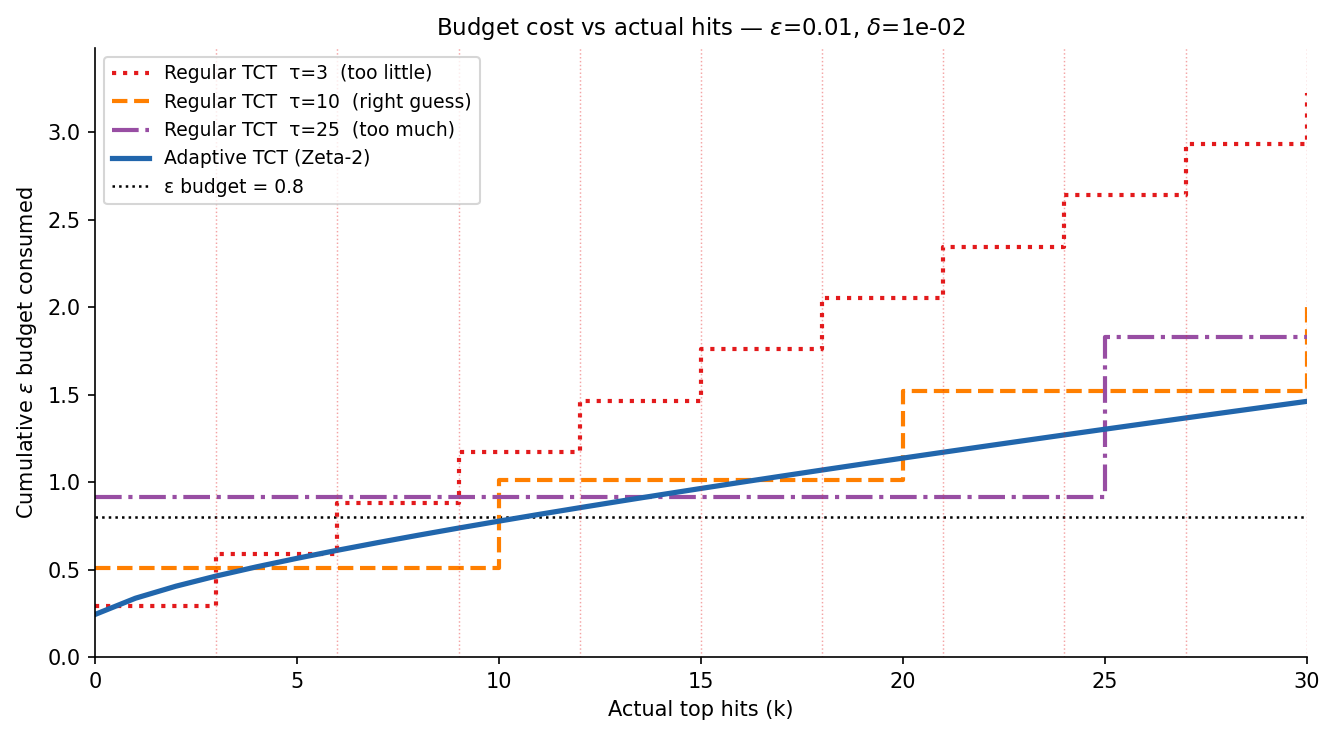

Budget consumed after k hits (budget = 0.8):
   k       Reg τ=3      Reg τ=10      Reg τ=25      Adaptive
------------------------------------------------------------
   0       0.2933        0.5075        0.9138*       0.2437 
   3       0.5867        0.5075        0.9138*       0.4635 
   6       0.8800*       0.5075        0.9138*       0.6106 
   9       1.1734*       0.5075        0.9138*       0.7375 
  10       1.1734*       1.0151*       0.9138*       0.7772 
  11       1.1734*       1.0151*       0.9138*       0.8160*
  12       1.4667*       1.0151*       0.9138*       0.8540*
  15       1.7600*       1.0151*       0.9138*       0.9640*
  20       2.0534*       1.5226*       0.9138*       1.1375*
  25       2.6401*       1.5226*       1.8277*       1.3027*
* = exceeds budget


In [3]:
MAX_K = 30  # show cost up to 30 actual top hits
k_range = list(range(MAX_K + 1))

def regular_cost_at_k(tau, epsilon, delta, k):
    """
    Total budget consumed after k actual top hits under regular TCT.

    At hit k=tau, you've exhausted your prepaid allotment and immediately
    prepay the next chunk. Cost jumps at exactly k=tau, 2*tau, 3*tau, ...
    n_chunks = floor(k/tau) + 1  (initial registration + re-registrations)
    """
    qq   = 1.0 / (math.exp(epsilon) + 1.0)
    beta = math.log(1.0 / delta)
    at   = (beta + math.sqrt(beta**2 + 2*beta*tau)) / tau
    Kt   = (1.0 + at) / qq * tau
    chunk = Kt * epsilon
    n_chunks = math.floor(k / tau) + 1  # +1 for initial registration; jumps at k=tau, 2*tau, ...
    return n_chunks * chunk

def adaptive_cost_at_k(epsilon, delta, k):
    """
    Total budget consumed after k actual top hits under adaptive TCT.

    Registration sets cx=1 (pays K_1·ε). Each hit increments cx by 1 and
    pays K_{cx+1} - K_{cx}. After k hits cx=k+1, so total = K_{k+1}·ε.
    """
    acc = AdaptiveTCTAccountant(epsilon, delta)
    return acc.budget_cost(acc.compositions(k + 1))

# Pre-compute curves
c_low   = [regular_cost_at_k(TAU_LOW,   EPSILON, DELTA, k) for k in k_range]
c_match = [regular_cost_at_k(TAU_MATCH, EPSILON, DELTA, k) for k in k_range]
c_high  = [regular_cost_at_k(TAU_HIGH,  EPSILON, DELTA, k) for k in k_range]
c_adap  = [adaptive_cost_at_k(EPSILON, DELTA, k) for k in k_range]

fig, ax = plt.subplots(figsize=(9, 5))

# Regular TCT lines (staircases via step='post')
ax.step(k_range, c_low,   where='post', color='#e31a1c', lw=2, linestyle=':',
        label=rf'Regular TCT  τ={TAU_LOW}  (too little)')
ax.step(k_range, c_match, where='post', color='#ff7f00', lw=2, linestyle='--',
        label=rf'Regular TCT  τ={TAU_MATCH}  (right guess)')
ax.step(k_range, c_high,  where='post', color='#984ea3', lw=2, linestyle='-.',
        label=rf'Regular TCT  τ={TAU_HIGH}  (too much)')
# Adaptive TCT smooth curve
ax.plot(k_range, c_adap, color='#2166ac', lw=2.5, label='Adaptive TCT (Zeta-2)')

# Budget line
ax.axhline(EPS_BUDGET, color='black', lw=1.2, linestyle=':', zorder=0,
           label=f'ε budget = {EPS_BUDGET}')

# Annotate re-registration jumps for tau_low (occur at exact multiples of TAU_LOW)
for i in range(1, MAX_K // TAU_LOW + 1):
    k_jump = i * TAU_LOW
    if k_jump <= MAX_K:
        ax.axvline(k_jump, color='#e31a1c', lw=0.7, linestyle=':', alpha=0.4)

ax.set_xlabel('Actual top hits (k)')
ax.set_ylabel(r'Cumulative $\varepsilon$ budget consumed')
ax.set_title(
    rf'Budget cost vs actual hits — $\varepsilon$={EPSILON}, $\delta$={DELTA:.0e}',
    fontsize=11
)
ax.legend(loc='upper left', fontsize=9)
ax.set_xlim(0, MAX_K)
ax.set_ylim(0, max(max(c_high[:MAX_K+1]), max(c_low)) * 1.08)

plt.tight_layout()
plt.savefig('../figures/adaptivity_cost_curves.png', bbox_inches='tight', dpi=200)
plt.show()

# Summary table
print(f'Budget consumed after k hits (budget = {EPS_BUDGET}):')
print(f'{"k":>4}  {"Reg τ="+str(TAU_LOW):>12}  {"Reg τ="+str(TAU_MATCH):>12}  {"Reg τ="+str(TAU_HIGH):>12}  {"Adaptive":>12}')
print('-' * 60)
for k in [0, 3, 6, 9, 10, 11, 12, 15, 20, 25]:
    if k > MAX_K: continue
    def fmt(c): return f'{c:.4f}' + ('*' if c > EPS_BUDGET else ' ')
    print(f'{k:>4}  {fmt(c_low[k]):>12}  {fmt(c_match[k]):>12}  {fmt(c_high[k]):>12}  {fmt(c_adap[k]):>12}')
print('* = exceeds budget')

## Section 2: Simulation Setup

In [4]:
pop_cfg = PopulationConfig(
    n_users=N_USERS, alpha=POP_ALPHA, beta=POP_BETA,
    epsilon_budget=EPS_BUDGET,
    delta_budget=DELTA_BUDGET,
)

# Calibrate threshold once; reuse across scenarios
print('Calibrating threshold...')
calib_pop = generate_synthetic_population(pop_cfg, rng=np.random.default_rng(SEED))
T, hit_rate = set_threshold_for_hit_rate(
    calib_pop, EPSILON, TARGET_HIT,
    n_pilot=3000, rng=np.random.default_rng(SEED + 1)
)
print(f'T = {T:.2f},  empirical hit rate = {hit_rate:.4f}  (target {TARGET_HIT})')
actual_tops = hit_rate * N_ROUNDS
print(f'Expected top rounds in {N_ROUNDS} rounds ≈ {actual_tops:.1f}')
print(f'Expected per-user personal hits ≈ {actual_tops * mean_rate:.1f}  (mean rate={mean_rate:.2f})')

def run_sim(accountant_factory, seed=SEED):
    """Run one simulation; return (fraction_active_by_round, total_top_count, top_round_list)."""
    rng = np.random.default_rng(seed)
    pop = generate_synthetic_population(pop_cfg, rng=np.random.default_rng(seed))
    acc = accountant_factory()
    frac  = []
    tops  = 0
    top_rounds = []
    for r in range(N_ROUNDS):
        active = pop.active_users
        if not active:
            break
        parts = list(active)
        cnt, contribs = compute_round_conversions(parts, rng)
        is_top, _ = laplace_threshold_query(cnt, T, EPSILON, rng)
        if is_top:
            tops += 1
            top_rounds.append(r)
        for i, user in enumerate(parts):
            e, d = acc.charge(user=user, is_top=is_top,
                              contributed=contribs[i], round_num=r)
            user.epsilon_spent += e
            user.delta_spent   += d
        pop.drop_depleted()
        frac.append(pop.active_fraction)
    return frac, tops, top_rounds

def half_life(frac):
    for r, f in enumerate(frac):
        if f <= 0.5: return r
    return len(frac)

def pad_frac(frac, n):
    return list(frac) + ([frac[-1] if frac else 0.0] * (n - len(frac)))

Calibrating threshold...


T = 431.49,  empirical hit rate = 0.0800  (target 0.08)
Expected top rounds in 500 rounds ≈ 40.0
Expected per-user personal hits ≈ 20.0  (mean rate=0.50)


## Panel 1: Right Guess (τ = TAU_MATCH)

τ is set to approximately match the expected number of actual top rounds.
Regular and adaptive TCT should perform similarly — regular TCT is slightly cheaper
per-chunk (uses full δ), but the advantage is modest.

In [5]:
print(f'Panel 1: τ={TAU_MATCH} (right guess)')
frac_reg1, tops1, top_rounds1 = run_sim(lambda: RegularTCTAccountant(EPSILON, DELTA, TAU_MATCH))
frac_adp1, _,     _           = run_sim(lambda: AdaptiveTCTAccountant(EPSILON, DELTA))
hl_reg1 = half_life(frac_reg1); hl_adp1 = half_life(frac_adp1)
print(f'  Regular TCT  half-life = {hl_reg1} rounds')
print(f'  Adaptive TCT half-life = {hl_adp1} rounds')
print(f'  Total top rounds in sim: {tops1}')

Panel 1: τ=10 (right guess)


  Regular TCT  half-life = 500 rounds
  Adaptive TCT half-life = 500 rounds
  Total top rounds in sim: 19


## Panel 2: Too Little (τ = TAU_LOW)

τ is set well below the expected number of tops. Regular TCT must re-register
every τ hits, paying K_τ again each time. The cumulative re-registration cost
exhausts the budget faster than adaptive TCT's incremental payments.

In [6]:
print(f'Panel 2: τ={TAU_LOW} (too little)')
frac_reg2, tops2, _ = run_sim(lambda: RegularTCTAccountant(EPSILON, DELTA, TAU_LOW))
frac_adp2, _,     _ = run_sim(lambda: AdaptiveTCTAccountant(EPSILON, DELTA))
hl_reg2 = half_life(frac_reg2); hl_adp2 = half_life(frac_adp2)
print(f'  Regular TCT  half-life = {hl_reg2} rounds')
print(f'  Adaptive TCT half-life = {hl_adp2} rounds')

# Estimate re-registration events: users are dropped when ceiling exceeded
# Theoretical: max tops = floor(budget / chunk_cost) * tau
beta_std = math.log(1.0 / DELTA)
at_low   = (beta_std + math.sqrt(beta_std**2 + 2*beta_std*TAU_LOW)) / TAU_LOW
Kt_low   = (1.0 + at_low) / q * TAU_LOW
chunk_low = Kt_low * EPSILON
n_chunks  = math.floor(EPS_BUDGET / chunk_low)
max_tops  = n_chunks * TAU_LOW
print(f'  Theoretical max tops before dropout: {max_tops}  ({n_chunks} chunks × {TAU_LOW} tops)')

Panel 2: τ=3 (too little)


  Regular TCT  half-life = 270 rounds
  Adaptive TCT half-life = 500 rounds
  Theoretical max tops before dropout: 6  (2 chunks × 3 tops)


## Panel 3: Too Much (τ = TAU_HIGH)

τ is set far above the expected number of tops. The single registration
charge K_{τ_high} · ε exceeds the per-user budget — users are dropped
immediately at registration. Adaptive TCT charges only K_1 · ε at registration,
survives, and pays incrementally for each actual hit.

In [7]:
print(f'Panel 3: τ={TAU_HIGH} (too much)')
frac_reg3, tops3, _ = run_sim(lambda: RegularTCTAccountant(EPSILON, DELTA, TAU_HIGH))
frac_adp3, _,     _ = run_sim(lambda: AdaptiveTCTAccountant(EPSILON, DELTA))
hl_reg3 = half_life(frac_reg3); hl_adp3 = half_life(frac_adp3)

at_high  = (beta_std + math.sqrt(beta_std**2 + 2*beta_std*TAU_HIGH)) / TAU_HIGH
Kt_high  = (1.0 + at_high) / q * TAU_HIGH
chunk_high = Kt_high * EPSILON
print(f'  Regular TCT registration cost: {chunk_high:.4f}  (budget: {EPS_BUDGET})')
if chunk_high > EPS_BUDGET:
    print(f'  → Cost exceeds budget → ALL users dropped at registration')
print(f'  Regular TCT  half-life = {hl_reg3} rounds')
print(f'  Adaptive TCT half-life = {hl_adp3} rounds')

Panel 3: τ=25 (too much)
  Regular TCT registration cost: 0.9138  (budget: 0.8)
  → Cost exceeds budget → ALL users dropped at registration
  Regular TCT  half-life = 0 rounds
  Adaptive TCT half-life = 500 rounds


## Combined Figure

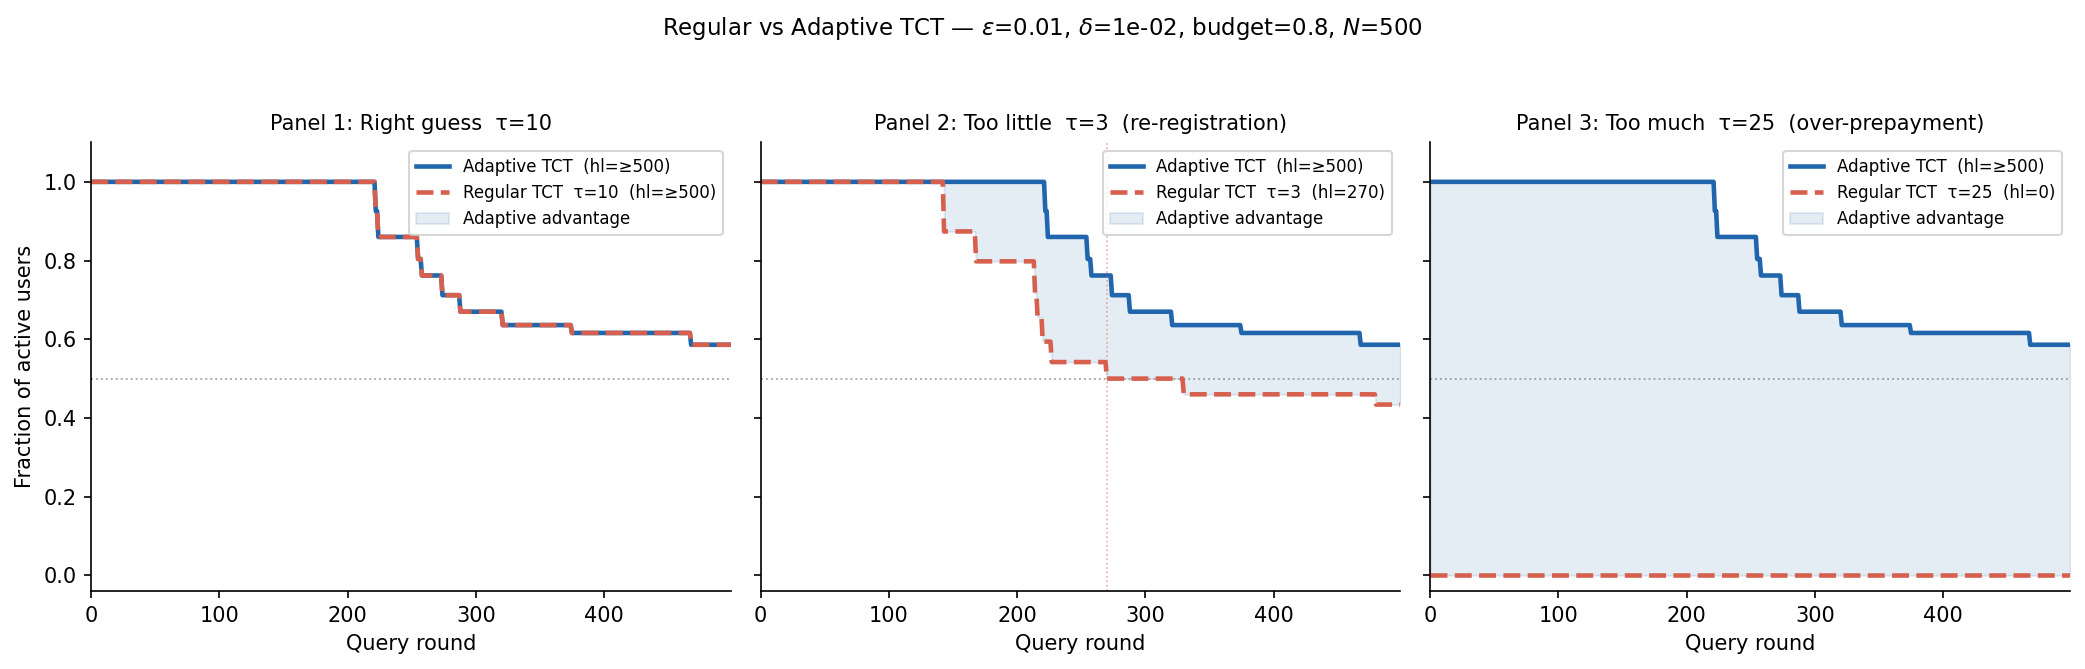

In [8]:
REG_COLOR  = '#d6604d'
ADAP_COLOR = '#2166ac'

scenarios = [
    (frac_reg1, frac_adp1, hl_reg1, hl_adp1,
     f'Panel 1: Right guess  τ={TAU_MATCH}',
     f'Both methods survive similarly.\nAdaptive hl={hl_adp1}, Regular hl={hl_reg1}'),
    (frac_reg2, frac_adp2, hl_reg2, hl_adp2,
     f'Panel 2: Too little  τ={TAU_LOW}  (re-registration)',
     f'Re-registration overhead exhausts budget.\nAdaptive hl={hl_adp2}, Regular hl={hl_reg2}'),
    (frac_reg3, frac_adp3, hl_reg3, hl_adp3,
     f'Panel 3: Too much  τ={TAU_HIGH}  (over-prepayment)',
     f'Over-prepayment → immediate dropout.\nAdaptive hl={hl_adp3}, Regular hl={hl_reg3}'),
]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)

n = N_ROUNDS
rnds = list(range(n))

for ax, (fr, fa, hlr, hla, title, note) in zip(axes, scenarios):
    pa = pad_frac(fa, n)
    pr = pad_frac(fr, n)

    ax.plot(rnds, pa, color=ADAP_COLOR, lw=2.2,
            label=f'Adaptive TCT  (hl={hla if hla < n else "≥"+str(n)})')
    ax.plot(rnds, pr, color=REG_COLOR,  lw=2.2, linestyle='--',
            label=f'Regular TCT  τ={TAU_LOW if "Low" in title or "little" in title else (TAU_MATCH if "Match" in title or "Right" in title else TAU_HIGH)}  (hl={hlr if hlr < n else "≥"+str(n)})')

    # Shade the advantage region
    ax.fill_between(rnds, pr, pa, where=[a > r for a, r in zip(pa, pr)],
                    alpha=0.12, color=ADAP_COLOR, label='Adaptive advantage')

    ax.axhline(0.5, color='#aaa', lw=0.9, linestyle=':', zorder=0)
    if hlr < n - 2:
        ax.axvline(hlr, color=REG_COLOR,  lw=0.8, linestyle=':', alpha=0.5)
    if hla < n - 2:
        ax.axvline(hla, color=ADAP_COLOR, lw=0.8, linestyle=':', alpha=0.5)

    ax.set_xlabel('Query round')
    ax.set_title(title, fontsize=10)
    ax.set_xlim(0, n - 1)
    ax.set_ylim(-0.04, 1.10)
    ax.legend(loc='upper right', fontsize=8)

axes[0].set_ylabel('Fraction of active users')

fig.suptitle(
    rf'Regular vs Adaptive TCT — $\varepsilon$={EPSILON}, $\delta$={DELTA:.0e}, '
    rf'budget={EPS_BUDGET}, $N$={N_USERS}',
    fontsize=11,
)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig('../figures/adaptivity_advantage.png', bbox_inches='tight', dpi=200)
plt.show()

## Section 3: Budget Waste Decomposition

For a user who contributed to exactly k actual top rounds, how much budget
did each accountant charge, and how much was wasted on phantom hits?

Total top rounds: 19,  representative per-user hits ≈ 10
  (mean conversion rate 0.50 × 19 top rounds)

Budget actually charged after 10 personal hits:
  Adaptive TCT cost = 0.7772

        Scenario  Total cost  Adaptive cost  Extra vs adaptive  Extra %
τ=3 (too little)      1.1734         0.7772             0.3961  50.9629
    τ=10 (right)      0.5075         0.7772            -0.2697 -34.7009
 τ=25 (too much)      0.9138         0.7772             0.1366  17.5719

Optimal tau for k=10 hits: tau=10  cost=0.5075  (cheaper than adaptive 0.7772)


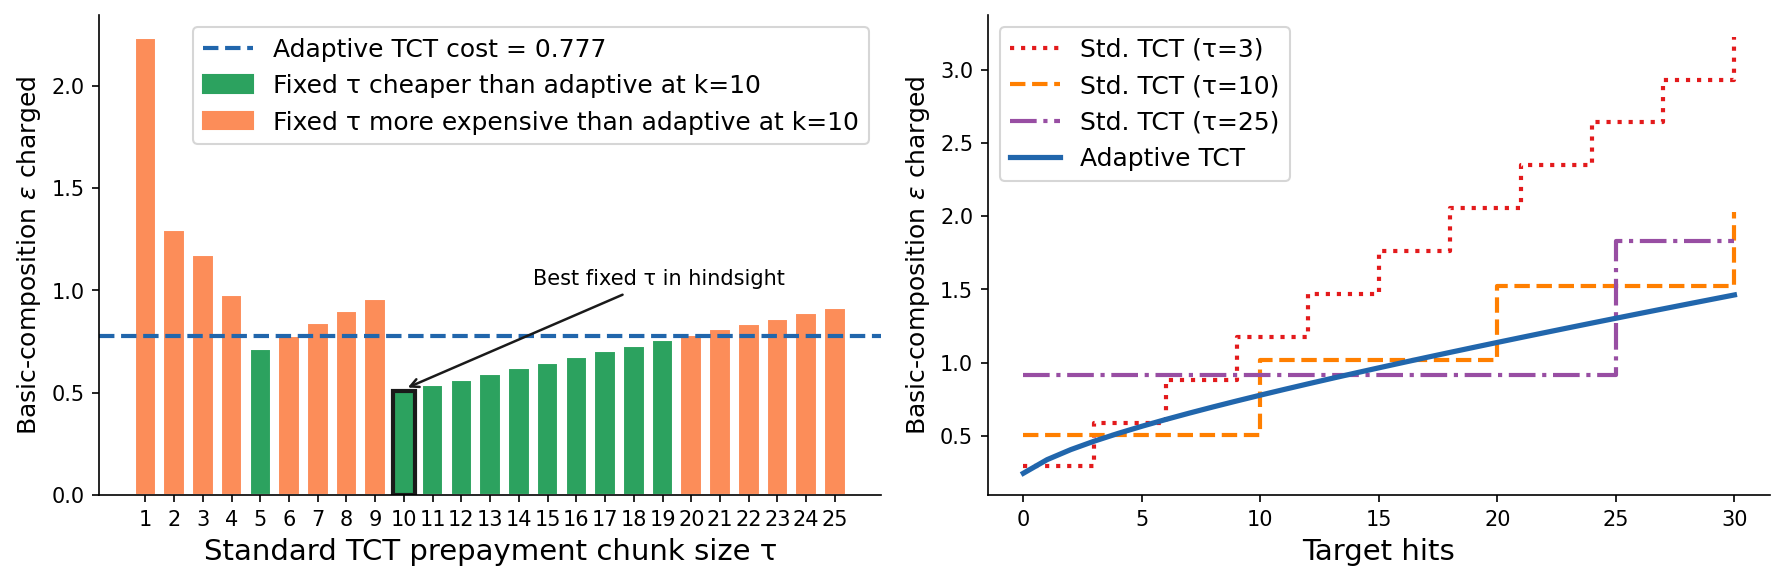

In [66]:
# Waste decomposition uses a representative per-user hit count.
rep_hits = max(1, round(tops1 * mean_rate))
print(f'Total top rounds: {tops1},  representative per-user hits ≈ {rep_hits}')
print(f'  (mean conversion rate {mean_rate:.2f} × {tops1} top rounds)')
print()

acc_adap  = AdaptiveTCTAccountant(EPSILON, DELTA)
adaptive_cost_rep = acc_adap.budget_cost(acc_adap.compositions(rep_hits + 1))


def regular_charged_at_k(tau, epsilon, delta, k):
    """
    Budget actually charged after k hits — matches simulator (> ceiling check).
    Re-registration fires at hit tau+1, 2*tau+1, ..., so n_chunks = ceil(k/tau).
    No jump at k=tau; jump at k=tau+1.
    """
    qq   = 1.0 / (math.exp(epsilon) + 1.0)
    beta = math.log(1.0 / delta)
    at   = (beta + math.sqrt(beta**2 + 2*beta*tau)) / tau
    Kt   = (1.0 + at) / qq * tau
    chunk = Kt * epsilon
    n_chunks = max(1, math.ceil(k / tau)) if k > 0 else 1
    return n_chunks * chunk


rows = []
for tau, label in [(TAU_LOW, f'τ={TAU_LOW} (too little)'),
                   (TAU_MATCH, f'τ={TAU_MATCH} (right)'),
                   (TAU_HIGH, f'τ={TAU_HIGH} (too much)')]:
    cost_k = regular_charged_at_k(tau, EPSILON, DELTA, rep_hits)
    waste  = cost_k - adaptive_cost_rep
    rows.append({
        'Scenario': label,
        'Total cost': cost_k,
        'Adaptive cost': adaptive_cost_rep,
        'Extra vs adaptive': waste,
        'Extra %': 100 * waste / adaptive_cost_rep,
    })

df = pd.DataFrame(rows)
print(f'Budget actually charged after {rep_hits} personal hits:')
print(f'  Adaptive TCT cost = {adaptive_cost_rep:.4f}')
print()
print(df.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

# Find the cheapest tau for exactly rep_hits
tau_sweep   = list(range(1, 26))
costs_sweep = [regular_charged_at_k(tau, EPSILON, DELTA, rep_hits) for tau in tau_sweep]
opt_tau  = tau_sweep[costs_sweep.index(min(costs_sweep))]
opt_cost = min(costs_sweep)
print(f'\nOptimal tau for k={rep_hits} hits: tau={opt_tau}  cost={opt_cost:.4f}  '
      f'({"cheaper" if opt_cost < adaptive_cost_rep else "costlier"} than adaptive {adaptive_cost_rep:.4f})')

# Color: green = cheaper than adaptive, orange = more expensive
COLOR_BETTER = '#2ca25f'
COLOR_WORSE  = '#fc8d59'

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Left panel: actually-charged cost vs tau (1..25) at rep_hits personal hits
ax = axes[0]
bar_colors = [COLOR_BETTER if c <= adaptive_cost_rep else COLOR_WORSE for c in costs_sweep]
bars = ax.bar(tau_sweep, costs_sweep, color=bar_colors, edgecolor='white', width=0.75)

# Bold border on the optimal tau bar
opt_idx = tau_sweep.index(opt_tau)
bars[opt_idx].set_edgecolor('#1a1a1a')
bars[opt_idx].set_linewidth(2.0)

ax.axhline(adaptive_cost_rep, color=ADAP_COLOR, lw=2, linestyle='--',
           label=f'Adaptive TCT = {adaptive_cost_rep:.3f}')

# Annotation arrow at the optimal bar
ann_xoffset = 4.5 if opt_tau <= 15 else -4.5
ann_ha      = 'left' if opt_tau <= 15 else 'right'
ax.annotate(
    f'Best fixed τ in hindsight',
    xy=(opt_tau, opt_cost + 0.01),
    xytext=(opt_tau + ann_xoffset, opt_cost + 0.50),
    fontsize=10, ha=ann_ha, va='bottom',
    arrowprops=dict(arrowstyle='->', color='#1a1a1a', lw=1.2),
)

ax.set_xlabel('Standard TCT prepayment chunk size τ', fontsize=14)
ax.set_ylabel(r'Basic-composition $\varepsilon$ charged', fontsize=12)
# ax.set_title(f'Cost after {rep_hits} hits as a function of fixed prepayment chunk size τ', fontsize=12)
ax.set_xticks(tau_sweep)

better_patch = mpatches.Patch(color=COLOR_BETTER, label=f'Fixed τ cheaper than adaptive at k={rep_hits}')
worse_patch  = mpatches.Patch(color=COLOR_WORSE,  label=f'Fixed τ more expensive than adaptive at k={rep_hits}')
ax.legend(handles=[ax.get_legend_handles_labels()[0][0], better_patch, worse_patch],
          labels=[f'Adaptive TCT cost = {adaptive_cost_rep:.3f}',
                  f'Fixed τ cheaper than adaptive at k={rep_hits}',
                  f'Fixed τ more expensive than adaptive at k={rep_hits}'],
          fontsize=12, loc='upper right')

# Right panel: committed cost curves (floor+1, jump at k=tau)
ax = axes[1]
k_vals = list(range(0, MAX_K + 1))

curve_specs = [
    (TAU_LOW,   '#e31a1c', ':',  rf'Std. TCT (τ={TAU_LOW})'),
    (TAU_MATCH, '#ff7f00', '--', rf'Std. TCT (τ={TAU_MATCH})'),
    (TAU_HIGH,  '#984ea3', '-.', rf'Std. TCT (τ={TAU_HIGH})'),
]
for tau, col, ls, lbl in curve_specs:
    vals = [regular_cost_at_k(tau, EPSILON, DELTA, k) for k in k_vals]
    ax.step(k_vals, vals, where='post', color=col, lw=2, linestyle=ls, label=lbl)
    

adap_vals = [adaptive_cost_at_k(EPSILON, DELTA, k) for k in k_vals]
ax.plot(k_vals, adap_vals, color=ADAP_COLOR, lw=2.5, label='Adaptive TCT')


ax.set_xlabel('Target hits', fontsize=14)
ax.set_ylabel(r'Basic-composition $\varepsilon$ charged', fontsize=12)
#ax.set_title('Batched fixed-τ TCT',  fontsize=14)
ax.legend(fontsize=12, loc='upper left')

# fig.suptitle(
  #  rf'Cost of choosing the fixed TCT hit count in advance — $\varepsilon$={EPSILON}, $\delta$={DELTA:.0e}',
   # fontsize=22,
# )
plt.tight_layout()
fig.subplots_adjust(top=0.85)
plt.savefig('../figures/adaptivity_waste.png', bbox_inches='tight', dpi=200)
plt.show()


## Section 4: Budget Degradation & User Retention Over Time

For each scenario, two curves are shown side-by-side across all three panels:

- **User retention** (top row): fraction of initial users still active vs query round.
- **Budget degradation** (bottom row): average ε budget remaining across *all* initial users,
  clamped at 0 for dropped users. Shows how fast the population's privacy budget depletes — and
  how much of it is consumed prematurely by wrong prepayment guesses.

In [10]:
def run_sim_detailed(accountant_factory, seed=SEED):
    """
    Run simulation, returning per-round retention and budget degradation arrays.

    Returns:
        frac          — fraction of initially active users still active each round
        avg_remaining — mean ε remaining across ALL initial users (dropped → clamped at 0)
    """
    rng = np.random.default_rng(seed)
    pop = generate_synthetic_population(pop_cfg, rng=np.random.default_rng(seed))
    acc = accountant_factory()
    frac          = []
    avg_remaining = []

    for r in range(N_ROUNDS):
        active = pop.active_users
        if active:
            parts = list(active)
            cnt, contribs = compute_round_conversions(parts, rng)
            is_top, _ = laplace_threshold_query(cnt, T, EPSILON, rng)
            for i, user in enumerate(parts):
                e, d = acc.charge(user=user, is_top=is_top,
                                  contributed=contribs[i], round_num=r)
                user.epsilon_spent += e
                user.delta_spent   += d
            pop.drop_depleted()

        frac.append(pop.active_fraction)
        avg_remaining.append(
            float(np.mean([max(0.0, u.epsilon_remaining) for u in pop.all_users]))
        )

    return frac, avg_remaining


# One run per accountant — shared seed so only TCT accounting differs
print('Running detailed simulations...')
detail = {}
configs = [
    ('Adaptive TCT',             lambda: AdaptiveTCTAccountant(EPSILON, DELTA),              ADAP_COLOR, '-'),
    (f'Regular τ={TAU_MATCH} (right)',   lambda: RegularTCTAccountant(EPSILON, DELTA, TAU_MATCH), '#ff7f00', '--'),
    (f'Regular τ={TAU_LOW} (too little)',lambda: RegularTCTAccountant(EPSILON, DELTA, TAU_LOW),   '#e31a1c', ':'),
    (f'Regular τ={TAU_HIGH} (too much)', lambda: RegularTCTAccountant(EPSILON, DELTA, TAU_HIGH),  '#984ea3', '-.'),
]
for label, factory, color, ls in configs:
    fr, rem = run_sim_detailed(factory)
    detail[label] = {'frac': fr, 'rem': rem, 'color': color, 'ls': ls}
    hl = half_life(fr)
    print(f'  {label:<34}  hl={hl if hl < N_ROUNDS else "≥500":>5}  '
          f'final avg remaining = {rem[-1]:.4f}')

Running detailed simulations...
  Adaptive TCT                        hl= ≥500  final avg remaining = 0.1419


  Regular τ=10 (right)                hl= ≥500  final avg remaining = 0.1714
  Regular τ=3 (too little)            hl=  270  final avg remaining = 0.1653


  Regular τ=25 (too much)             hl=    0  final avg remaining = 0.0000


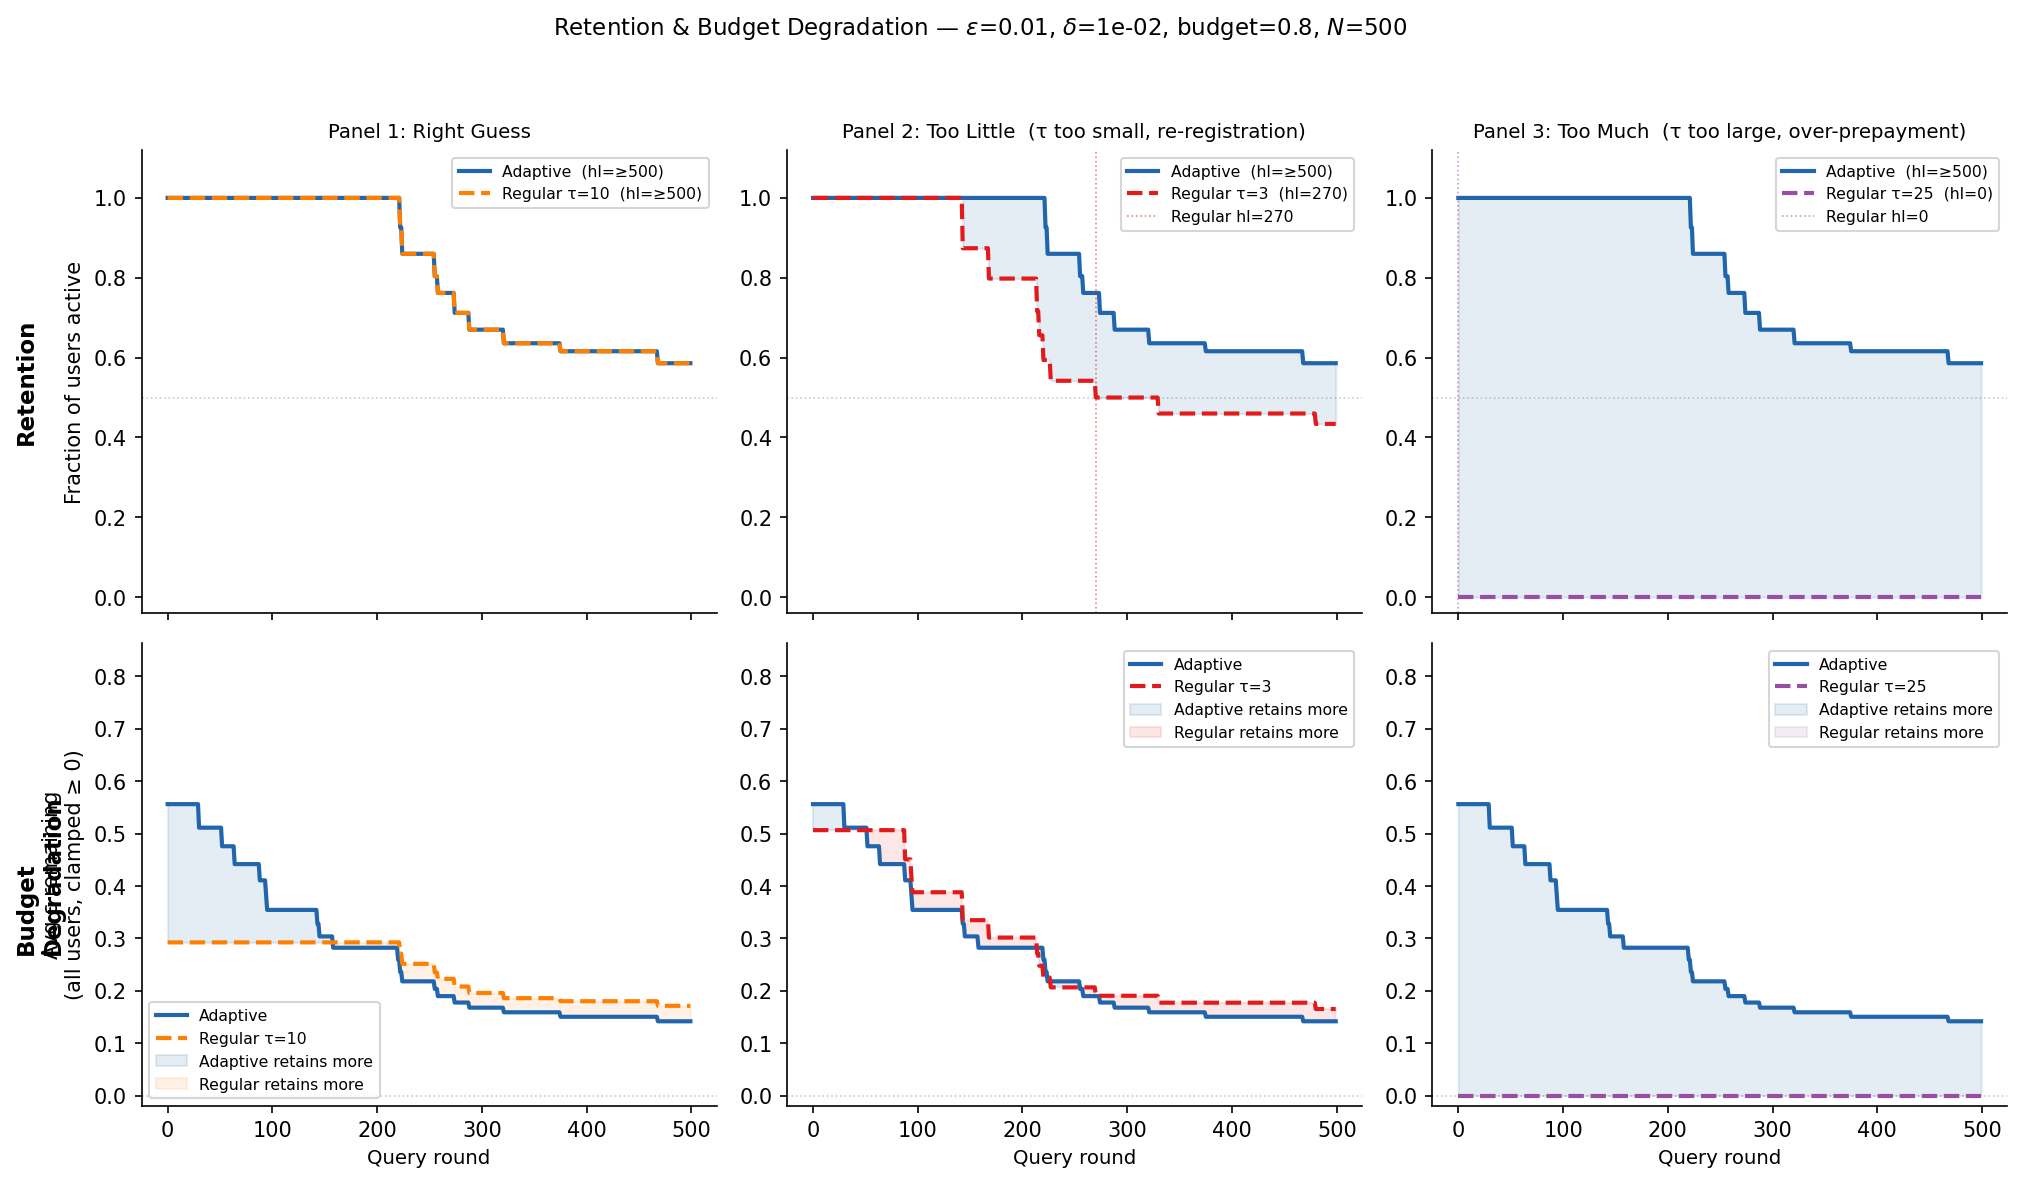

Average ε remaining after round 0 (= initial charge at registration):
  Adaptive TCT                        round 0: 0.5563  (charged 0.2437)    final: 0.1419
  Regular τ=10 (right)                round 0: 0.2925  (charged 0.5075)    final: 0.1714
  Regular τ=3 (too little)            round 0: 0.5067  (charged 0.2933)    final: 0.1653
  Regular τ=25 (too much)             round 0: 0.0000  (charged 0.8000)    final: 0.0000


In [11]:
rnds = list(range(N_ROUNDS))

# 3 columns = scenarios; 2 rows = retention (top) + budget remaining (bottom)
panel_cols = [
    (f'Regular τ={TAU_MATCH} (right)',   TAU_MATCH, 'Panel 1: Right Guess'),
    (f'Regular τ={TAU_LOW} (too little)', TAU_LOW,  'Panel 2: Too Little  (τ too small, re-registration)'),
    (f'Regular τ={TAU_HIGH} (too much)', TAU_HIGH,  'Panel 3: Too Much  (τ too large, over-prepayment)'),
]

adp = detail['Adaptive TCT']
adp_frac = pad_frac(adp['frac'], N_ROUNDS)
adp_rem  = pad_frac(adp['rem'],  N_ROUNDS)

fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True)

for col, (reg_key, tau_val, col_title) in enumerate(panel_cols):
    reg = detail[reg_key]
    reg_frac = pad_frac(reg['frac'], N_ROUNDS)
    reg_rem  = pad_frac(reg['rem'],  N_ROUNDS)
    reg_color = reg['color']
    hl_reg = half_life(reg['frac'])
    hl_adp = half_life(adp['frac'])

    # ── Row 0: User retention ─────────────────────────────────────────────
    ax = axes[0, col]
    ax.plot(rnds, adp_frac, color=ADAP_COLOR, lw=2,
            label=f'Adaptive  (hl={"≥500" if hl_adp >= N_ROUNDS else hl_adp})')
    ax.plot(rnds, reg_frac, color=reg_color, lw=2, linestyle='--',
            label=f'Regular τ={tau_val}  (hl={"≥500" if hl_reg >= N_ROUNDS else hl_reg})')
    ax.fill_between(rnds, reg_frac, adp_frac,
                    where=[a > r for a, r in zip(adp_frac, reg_frac)],
                    alpha=0.12, color=ADAP_COLOR)
    ax.axhline(0.5, color='#ccc', lw=0.8, linestyle=':', zorder=0)
    if hl_reg < N_ROUNDS - 2:
        ax.axvline(hl_reg, color=reg_color, lw=0.8, linestyle=':', alpha=0.55,
                   label=f'Regular hl={hl_reg}')
    ax.set_ylim(-0.04, 1.12)
    ax.set_title(col_title, fontsize=9.5)
    ax.legend(fontsize=7.5, loc='upper right')
    if col == 0:
        ax.set_ylabel('Fraction of users active', fontsize=10)

    # ── Row 1: Budget degradation ─────────────────────────────────────────
    ax = axes[1, col]
    ax.plot(rnds, adp_rem, color=ADAP_COLOR, lw=2, label='Adaptive')
    ax.plot(rnds, reg_rem, color=reg_color, lw=2, linestyle='--', label=f'Regular τ={tau_val}')
    # Shade gap: adaptive retains more budget → positive area above regular
    ax.fill_between(rnds, reg_rem, adp_rem,
                    where=[a > r for a, r in zip(adp_rem, reg_rem)],
                    alpha=0.12, color=ADAP_COLOR, label='Adaptive retains more')
    ax.fill_between(rnds, adp_rem, reg_rem,
                    where=[r > a for a, r in zip(adp_rem, reg_rem)],
                    alpha=0.10, color=reg_color, label='Regular retains more')
    ax.axhline(0.0, color='#ccc', lw=0.8, linestyle=':', zorder=0)
    ax.set_ylim(-0.02, EPS_BUDGET * 1.08)
    ax.set_xlabel('Query round', fontsize=9.5)
    ax.legend(fontsize=7.5, loc='lower left' if col == 0 else 'upper right')
    if col == 0:
        ax.set_ylabel('Avg ε remaining\n(all users, clamped ≥ 0)', fontsize=10)

# Row labels
axes[0, 0].annotate('Retention', xy=(-0.22, 0.5), xycoords='axes fraction',
                     fontsize=11, fontweight='bold', va='center', rotation=90)
axes[1, 0].annotate('Budget\nDegradation', xy=(-0.22, 0.5), xycoords='axes fraction',
                     fontsize=11, fontweight='bold', va='center', rotation=90)

fig.suptitle(
    rf'Retention & Budget Degradation — $\varepsilon$={EPSILON}, $\delta$={DELTA:.0e}, '
    rf'budget={EPS_BUDGET}, $N$={N_USERS}',
    fontsize=11,
)
plt.tight_layout(rect=[0.04, 0, 1, 0.95])
plt.savefig('../figures/adaptivity_retention_budget.png', bbox_inches='tight', dpi=200)
plt.show()

# Key budget numbers at round 0 and final round
print('Average ε remaining after round 0 (= initial charge at registration):')
for label, d in detail.items():
    r0 = d['rem'][0]
    rf = d['rem'][-1]
    print(f'  {label:<34}  round 0: {r0:.4f}  (charged {EPS_BUDGET - r0:.4f})  '
          f'  final: {rf:.4f}')

## Summary

In [12]:
print('=== Adaptivity Advantage Summary ===')
print(f'ε={EPSILON}, δ={DELTA:.0e}, budget={EPS_BUDGET}, N_ROUNDS={N_ROUNDS}, N_USERS={N_USERS}')
print(f'Population: Beta({POP_ALPHA},{POP_BETA}), mean rate={mean_rate:.2f}')
print(f'Total top rounds: {tops1},  rep. per-user hits: {rep_hits}')
print()

print(f'{"Accountant":<22}  {"Panel 1 hl":>10}  {"Panel 2 hl":>10}  {"Panel 3 hl":>10}  {"Cost@{rep} hits".format(rep=rep_hits):>12}')
print('-' * 72)
rows_sum = [
    ('Adaptive TCT',         hl_adp1, hl_adp2, hl_adp3, adaptive_cost_rep),
    (f'Regular τ={TAU_MATCH} (right)',   hl_reg1, None,    None,    regular_cost_at_k(TAU_MATCH, EPSILON, DELTA, rep_hits)),
    (f'Regular τ={TAU_LOW} (too little)', None,  hl_reg2, None,    regular_cost_at_k(TAU_LOW,   EPSILON, DELTA, rep_hits)),
    (f'Regular τ={TAU_HIGH} (too much)',  None,  None,    hl_reg3, regular_cost_at_k(TAU_HIGH,  EPSILON, DELTA, rep_hits)),
]
for name, h1, h2, h3, cost in rows_sum:
    def fh(x): return f'{x:>10}' if x is not None else f'{"—":>10}'
    star = '*' if cost > EPS_BUDGET else ' '
    print(f'{name:<22}  {fh(h1)}  {fh(h2)}  {fh(h3)}  {cost:>11.4f}{star}')
print('* = cost exceeds budget')

print()
print('Key takeaways:')
print(f'  Panel 1 (right guess, τ={TAU_MATCH}):')
print(f'    Regular hl={hl_reg1}, Adaptive hl={hl_adp1} — similar survival when τ is correct')
print(f'  Panel 2 (too little, τ={TAU_LOW}):')
adv2 = hl_adp2 - hl_reg2 if hl_adp2 < N_ROUNDS else f'>{N_ROUNDS - hl_reg2}'
print(f'    Adaptive advantage = +{adv2} rounds  (re-registration overhead exhausts budget)')
print(f'  Panel 3 (too much, τ={TAU_HIGH}):')
print(f'    Regular hl={hl_reg3} (drops at registration), Adaptive hl={hl_adp3}')
print(f'    Over-prepayment wastes {100*(regular_cost_at_k(TAU_HIGH,EPSILON,DELTA,rep_hits) - adaptive_cost_rep)/adaptive_cost_rep:.0f}% extra budget vs adaptive')

=== Adaptivity Advantage Summary ===
ε=0.01, δ=1e-02, budget=0.8, N_ROUNDS=500, N_USERS=500
Population: Beta(1.0,1.0), mean rate=0.50
Total top rounds: 19,  rep. per-user hits: 10

Accountant              Panel 1 hl  Panel 2 hl  Panel 3 hl  Cost@10 hits
------------------------------------------------------------------------
Adaptive TCT                   500         500         500       0.7772 
Regular τ=10 (right)           500           —           —       1.0151*
Regular τ=3 (too little)           —         270           —       1.1734*
Regular τ=25 (too much)           —           —           0       0.9138*
* = cost exceeds budget

Key takeaways:
  Panel 1 (right guess, τ=10):
    Regular hl=500, Adaptive hl=500 — similar survival when τ is correct
  Panel 2 (too little, τ=3):
    Adaptive advantage = +>230 rounds  (re-registration overhead exhausts budget)
  Panel 3 (too much, τ=25):
    Regular hl=0 (drops at registration), Adaptive hl=500
    Over-prepayment wastes 18% extra 